# D01-GN — GMM trên RFM + AOV + Diversity với winsorization P99 (cap → log1p + Standard + PCA 90%)

Thí nghiệm **D01-GN** (người chạy: Nguyên) theo chiến lược model. So với C01, **chỉ thêm một bước winsorization ở cấp khách**: cắt (cap) các giá trị lớn hơn phân vị 99 của Frequency, Monetary, AOV và Diversity về đúng ngưỡng đó, **giữ nguyên Recency và không xóa khách nào**. Pipeline: làm sạch → 5 feature → **cap P99** → `log1p` → StandardScaler → PCA giữ ≥ 90% phương sai → GMM. Đây là nhánh chính của nhóm D; D02, D03, D04 so với kết quả này.

Cài đặt GMM, lưới `k × covariance_type` và quy tắc chọn giữ nguyên như C01-GN và GMM của Thuận. Bảng chiến lược không ghi ngưỡng cap của D01; nhóm đã dùng P99 cho D04 và E02–E04 (D02 dùng P95, D03 dùng P99.5), nên D01 dùng P99 để nhất quán. C01 được dựng lại ngay trong notebook để so cùng điều kiện. Mã "GN" được hiểu là GMM.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
CAP_FEATURES = ["Frequency", "Monetary", "AOV", "Diversity"]   # D01: cap các biến này; Recency giữ nguyên
CAP_Q = 99                        # phân vị cap (%); D02 = 95, D03 = 99.5
PCA_VAR = 0.90                    # giữ ít nhất 90% phương sai (giống C01)
RANDOM_STATE = 42                 # từ đây đến MIN_CLUSTER_FRAC: giống C01-GN / GMM của Thuận
N_INIT = 10
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01           # điều kiện chọn: mỗi cụm >= 1% số khách

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore", category=UserWarning)

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01..C04), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# AOV = avg_order_value, Diversity = n_stock_codes (số mã hàng khác nhau của khách)
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={"avg_order_value": "AOV", "n_stock_codes": "Diversity"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4.327 khách, 5 feature, không thiếu giá trị, không có giá trị âm. Cùng tệp đặc trưng 4.327 khách với C01 và các thí nghiệm A–C. Đuôi phải rất dài: Monetary lớn nhất 278.748 trong khi trung vị khoảng 658; Frequency lớn nhất 206 trong khi trung vị 2. Winsorization nhằm giảm ảnh hưởng của đuôi này lên mô hình mà vẫn giữ mọi khách.

## Winsorization P99 (cap)

Ngưỡng cap = phân vị 99 của từng biến trong `CAP_FEATURES`; giá trị lớn hơn ngưỡng bị kéo về ngưỡng. Recency không cap (ngưỡng vô cực). Cap áp dụng **trước** `log1p`, trên giá trị gốc.

In [3]:
caps = X.quantile(CAP_Q / 100)
caps[[c for c in FEATURES if c not in CAP_FEATURES]] = np.inf        # Recency giữ nguyên
capped = X.gt(caps, axis=1)
X_cap = X.clip(upper=caps, axis=1)

cap_report = pd.DataFrame({
    "cap": caps.replace(np.inf, np.nan).round(2),
    "customers_capped": capped.sum(),
    "customers_capped_pct": (100 * capped.mean()).round(2),
    "value_capped_pct": (100 * (X - X_cap).sum() / X.sum()).round(2),
})
n_capped = int(capped.any(axis=1).sum())
print(f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%) | số khách sau cap: {len(X_cap)} (không xóa khách nào)")
print("Monetary lớn nhất: ", round(X["Monetary"].max(), 2), "->", round(X_cap["Monetary"].max(), 2))
display_skew = pd.DataFrame({"skew_raw": X.skew(), "skew_sau_cap": X_cap.skew(),
                             "skew_cap_log1p": np.log1p(X_cap).skew(), "skew_log1p_khong_cap (C01)": np.log1p(X).skew()}).round(2)
print(); print(cap_report.to_string()); print(); print(display_skew.to_string())

Khách bị cap ở ít nhất 1 biến: 116 (2.68%) | số khách sau cap: 4327 (không xóa khách nào)
Monetary lớn nhất:  278748.02 -> 17279.06

                cap  customers_capped  customers_capped_pct  value_capped_pct
Recency         NaN                 0                  0.00              0.00
Frequency     30.00                42                  0.97              6.12
Monetary   17279.06                44                  1.02             21.62
AOV         1894.54                44                  1.02              4.45
Diversity    353.74                44                  1.02              3.50

           skew_raw  skew_sau_cap  skew_cap_log1p  skew_log1p_khong_cap (C01)
Recency        1.25          1.25           -0.33                       -0.33
Frequency     11.95          3.07            1.01                        1.21
Monetary      21.04          3.99            0.16                        0.35
AOV           11.94          2.72           -0.22                       -0.00
Diversit

**Nhận xét:** Ngưỡng P99 là Frequency 30, Monetary 17.279, AOV 1.895, Diversity 354. **116 khách (2,68%)** bị cap ở ít nhất một biến (mỗi biến khoảng 1% khách: Frequency 0,97%, Monetary, AOV và Diversity 1,02%), nhưng phần giá trị bị cắt lớn: **21,62% tổng Monetary**, 6,12% tổng Frequency, 4,45% AOV và 3,50% Diversity. Monetary lớn nhất giảm từ 278.748 xuống 17.279. Độ lệch giảm mạnh ngay sau cap (Frequency 11,95 → 3,07; Monetary 21,04 → 3,99; AOV 11,94 → 2,72; Diversity 6,92 → 2,18) và sau thêm `log1p` còn gần đối xứng (Frequency 1,01; Monetary 0,16; AOV −0,22; Diversity −0,29). Không khách nào bị xóa: vẫn đủ 4.327 khách.

## Chuẩn hóa và PCA giữ 90% phương sai

In [4]:
def make_prep(caps_values, n_components=None):
    steps = [("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps_values})),
             ("log1p", FunctionTransformer(np.log1p)),
             ("scaler", StandardScaler())]
    if n_components is not None:
        steps.append(("pca", PCA(n_components=n_components, svd_solver="full", random_state=RANDOM_STATE)))
    return Pipeline(steps)

def build_space(caps_values):
    Xs = make_prep(caps_values).fit_transform(X.values)
    ev = PCA(svd_solver="full").fit(Xs).explained_variance_ratio_
    cum = np.cumsum(ev)
    n = int(np.searchsorted(cum, PCA_VAR) + 1)
    pre = make_prep(caps_values, n).fit(X.values)
    return pre, pre.transform(X.values), ev, cum, n

caps_values = caps.to_numpy()
prep, Z, ev, cum, n_pc = build_space(caps_values)

print("Phương sai từng PC:", ev.round(4))
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")
pd.DataFrame(prep["pca"].components_, index=[f"PC{i+1}" for i in range(n_pc)], columns=FEATURES).round(3)

Phương sai từng PC: [0.6237 0.2025 0.0979 0.0747 0.0012]
Phương sai tích lũy: [0.6237 0.8262 0.9241 0.9988 1.    ]
Số PC giữ lại: 3 / 5 (phương sai giữ 92.41%)


,Recency,Frequency,Monetary,AOV,Diversity
PC1,-0.375,0.475,0.542,0.343,0.472
PC2,0.524,-0.366,0.178,0.748,0.037
PC3,0.755,0.417,0.087,-0.362,0.342


**Nhận xét:** Vẫn cần **3 PC** trên 5 biến để vượt 90% (giữ 92,41%; C01 cũng 3 PC, 92,40%), nên PCA thực sự giảm chiều như ở C01. Việc cắt đuôi gần như không đổi cấu trúc phương sai giữa các biến, nhưng thay đổi vị trí các khách ở đuôi trong không gian này.

## Chọn số thành phần k và loại hiệp phương sai

Chỉ số chính là **BIC** (thấp hơn là tốt hơn). Silhouette, DBI, CHI tính trên `Z` chỉ để tham khảo vì GMM là mô hình xác suất, các cụm có thể chồng lấn. Quét `k = 2..10` × 4 loại `covariance_type`.

In [5]:
def fit_gmm(Zs, k, cov):
    return GaussianMixture(n_components=int(k), covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                           reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Zs)

def sweep(Zs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = fit_gmm(Zs, k, cov)
            lab = gm.predict(Zs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Zs), "AIC": gm.aic(Zs),
                         "Silhouette": silhouette_score(Zs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Zs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Zs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    # BIC thấp nhất trong các cấu hình đã hội tụ và có mọi cụm >= 1% số khách
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")
print("k được chọn có chạm biên của lưới (k = 10) không:", int(best["k"]) == max(K_RANGE))
res.loc[res.groupby("covariance_type")["BIC"].idxmin()].round(4).reset_index(drop=True)

Chọn: full, k=7, BIC=36,889.0, Silhouette=0.1416, cụm nhỏ nhất=341
k được chọn có chạm biên của lưới (k = 10) không: False


,covariance_type,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
0,diag,10,37812.5557,37372.8443,0.2474,1.0877,1822.4947,119,True
1,full,7,36888.9525,36449.2411,0.1416,1.8113,1173.0007,341,True
2,spherical,10,37862.7036,37550.4448,0.2465,1.0912,1864.4262,134,True
3,tied,8,37758.2235,37522.4362,0.2029,1.2217,1394.0659,72,True


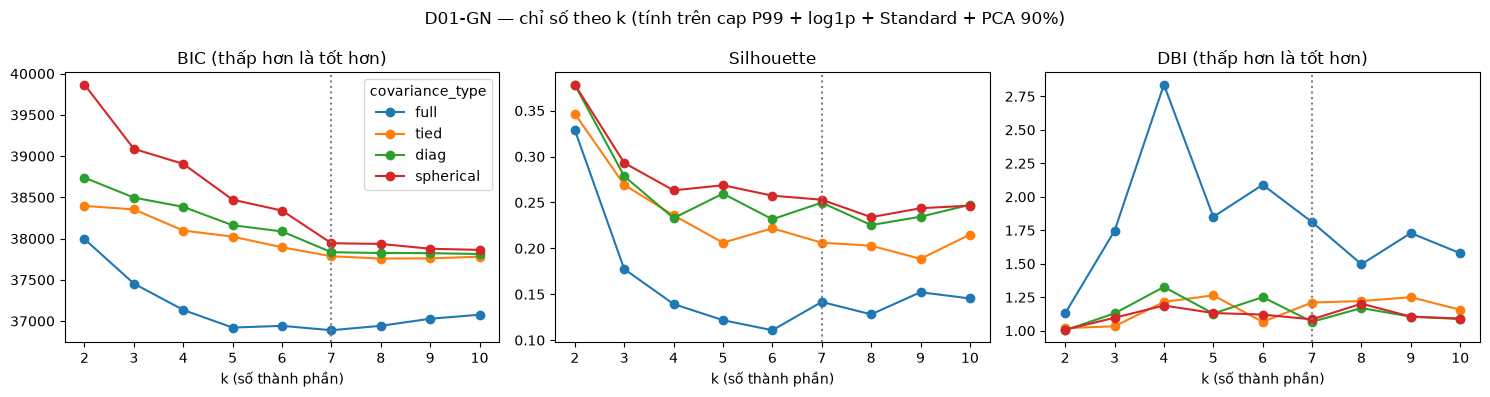

Silhouette cao nhất: {'covariance_type': 'spherical', 'k': 2, 'Silhouette': 0.3783087440197361, 'min_cluster': 1798}


,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
0,2,37994.3201,37873.2402,0.3290,1.1299,2711.8888,2121,True
1,3,37454.3491,37269.5429,0.1775,1.7456,1703.2128,956,True
2,4,37134.7635,36886.2310,0.1393,2.8377,1364.8914,830,True
3,5,36920.6852,36608.4264,0.1218,1.8505,1148.6577,554,True
4,6,36941.9088,36565.9236,0.1108,2.0897,1145.7494,418,True
5,7,36888.9525,36449.2411,0.1416,1.8113,1173.0007,341,True
6,8,36942.3739,36438.9362,0.1281,1.4966,1110.2830,134,True
7,9,37027.9598,36460.7957,0.1522,1.7293,1123.8153,73,True
8,10,37076.6049,36445.7145,0.1454,1.5788,1115.9186,71,True


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k (số thành phần)"); ax.set_title(col + (" (thấp hơn là tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("D01-GN — chỉ số theo k (tính trên cap P99 + log1p + Standard + PCA 90%)")
plt.tight_layout(); fig.savefig(FIG / "gmm_metrics.png", dpi=150, bbox_inches="tight"); plt.show()

print("Silhouette cao nhất:", res.loc[res["Silhouette"].idxmax(), ["covariance_type", "k", "Silhouette", "min_cluster"]].to_dict())
res[res["covariance_type"] == best["covariance_type"]].drop(columns="covariance_type").round(4)

**Nhận xét:** BIC thấp nhất ở **`full`, k = 7** (36.888,95), cụm nhỏ nhất 341 khách, không chạm biên k = 10. Cực tiểu **rõ hơn C01**: BIC của `full` là 36.920,7 ở k = 5, 36.941,9 ở k = 6, 36.889,0 ở k = 7 và 36.942,4 ở k = 8, nên k = 7 thấp hơn các k lân cận từ 31 điểm trở lên (ở C01, k = 6 và k = 7 chỉ chênh 3,2 điểm). Các loại hiệp phương sai khác đều cao hơn hẳn: `diag` và `spherical` có BIC thấp nhất ở biên k = 10 (37.812,6 và 37.862,7), `tied` ở k = 8 (37.758,2), tất cả cao hơn `full` k = 7 hơn 800 điểm.

## Train mô hình cuối

In [7]:
GM_ARGS = dict(n_components=int(best["k"]), covariance_type=best["covariance_type"], n_init=N_INIT, max_iter=MAX_ITER,
               tol=TOL, reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE)
model = Pipeline([("prep", make_prep(caps_values, n_pc)), ("gmm", GaussianMixture(**GM_ARGS))]).fit(X.values)
gm = model["gmm"]
assert np.allclose(model["prep"].transform(X.values), Z)             # pipeline cho đúng không gian đã quét
labels, proba = gm.predict(Z), gm.predict_proba(Z)
assert (labels == fit_gmm(Z, best["k"], best["covariance_type"]).predict(Z)).all()

print("Số khách theo cụm:", np.bincount(labels).tolist())
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_, "| BIC:", round(gm.bic(Z), 1))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4),
      "| CHI:", round(calinski_harabasz_score(Z, labels), 1))
soft = int((proba.max(axis=1) < 0.8).sum())
print(f"Khách có xác suất cụm cao nhất < 0,8: {soft} ({soft / len(X):.1%})")

Số khách theo cụm: [1313, 488, 492, 689, 341, 405, 599]
Hội tụ: True | số vòng EM: 31 | BIC: 36889.0
Silhouette: 0.1416 | DBI: 1.8113 | CHI: 1173.0
Khách có xác suất cụm cao nhất < 0,8: 3176 (73.4%)


**Nhận xét:** 7 cụm cỡ từ 341 đến 1.313 khách, hội tụ sau 31 vòng EM; Silhouette 0,1416, DBI 1,8113, CHI 1.173,0. Ranh giới giữa các cụm **rất mờ**: 3.176 khách (73,4%) có xác suất cụm cao nhất dưới 0,8, còn cao hơn C01 (69,7%), tức Silhouette tăng nhưng mô hình càng chia nhỏ thì chồng lấn càng nhiều.

## Hồ sơ cụm

Mô tả bằng trung vị **trên thang gốc, trước khi cap** (không phải log hay giá trị đã cắt). `Monetary_share_pct` là tỷ trọng tổng Monetary gốc của cụm.

In [8]:
prof = X.assign(cluster=labels, max_proba=proba.max(axis=1)).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    AOV=("AOV", "median"),
    Diversity=("Diversity", "median"),
    Monetary_sum=("Monetary", "sum"),
    max_proba_mean=("max_proba", "mean"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum")
prof.round(2)

,customers,Recency,Frequency,Monetary,AOV,Diversity,max_proba_mean,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,
0,1313,23.0,4.0,1122.38,274.25,61.0,0.65,30.34,20.80
1,488,71.5,1.0,309.17,307.84,17.0,0.72,11.28,2.21
2,492,23.0,2.0,226.98,134.88,15.0,0.68,11.37,2.91
3,689,117.0,2.0,495.77,277.19,27.0,0.58,15.92,4.57
4,341,68.0,3.0,2388.75,713.86,91.0,0.60,7.88,12.40
5,405,8.0,13.0,5180.52,425.99,176.0,0.76,9.36,55.14
6,599,281.0,1.0,216.50,205.86,13.0,0.76,13.84,1.97


**Nhận xét** (tên nhóm chỉ là cách gọi gợi ý từ trung vị, chưa phải kết luận của mô hình):
- Cụm 5 (405 khách, 9,4%): Recency 8, Frequency 13, Monetary ≈ 5.181, AOV ≈ 426, Diversity 176 → **khách hàng hàng đầu: mua rất gần, rất thường xuyên, chi nhiều**; chiếm **55,1%** tổng Monetary.
- Cụm 4 (341 khách, 7,9%): Recency 68, Frequency 3, Monetary ≈ 2.389, AOV ≈ 714, Diversity 91 → **mua ít lần nhưng giỏ lớn**; chiếm 12,4% Monetary.
- Cụm 0 (1.313 khách, 30,3%): Recency 23, Frequency 4, Monetary ≈ 1.122, AOV ≈ 274, Diversity 61 → **khách khá thường xuyên, còn gần**; 20,8% Monetary.
- Cụm 3 (689 khách, 15,9%): Recency 117, Frequency 2, Monetary ≈ 496 → **mua ít, đã khá lâu**; 4,6% Monetary.
- Cụm 2 (492 khách, 11,4%): Recency 23, Frequency 2, Monetary ≈ 227, AOV ≈ 135 → **mua ít, giỏ nhỏ, còn gần**; 2,9% Monetary.
- Cụm 1 (488 khách, 11,3%): Recency 72, Frequency 1, Monetary ≈ 309 → **mua một lần, thời gian trung bình**; 2,2% Monetary.
- Cụm 6 (599 khách, 13,8%): Recency 281, Frequency 1, Monetary ≈ 217 → **mua một lần, rất lâu chưa quay lại**; 2,0% Monetary.

Khác C01, nhóm giá trị cao nhất tách ra thành một cụm **lớn hơn nhiều** (405 khách, 9,4%, giữ 55,1% Monetary) thay vì một nhóm nhỏ 119 khách (2,8%).

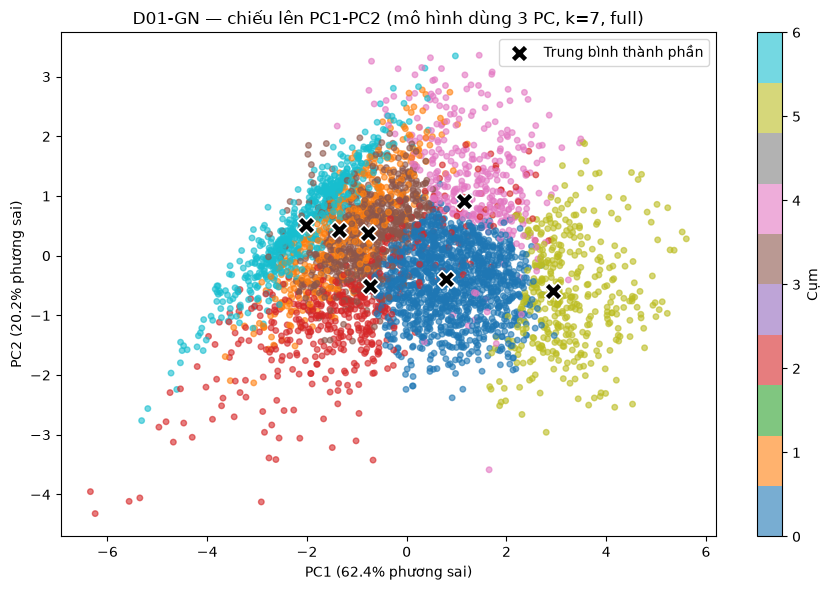

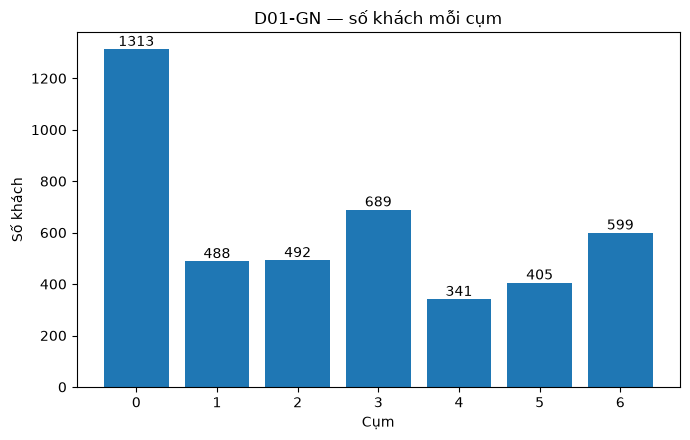

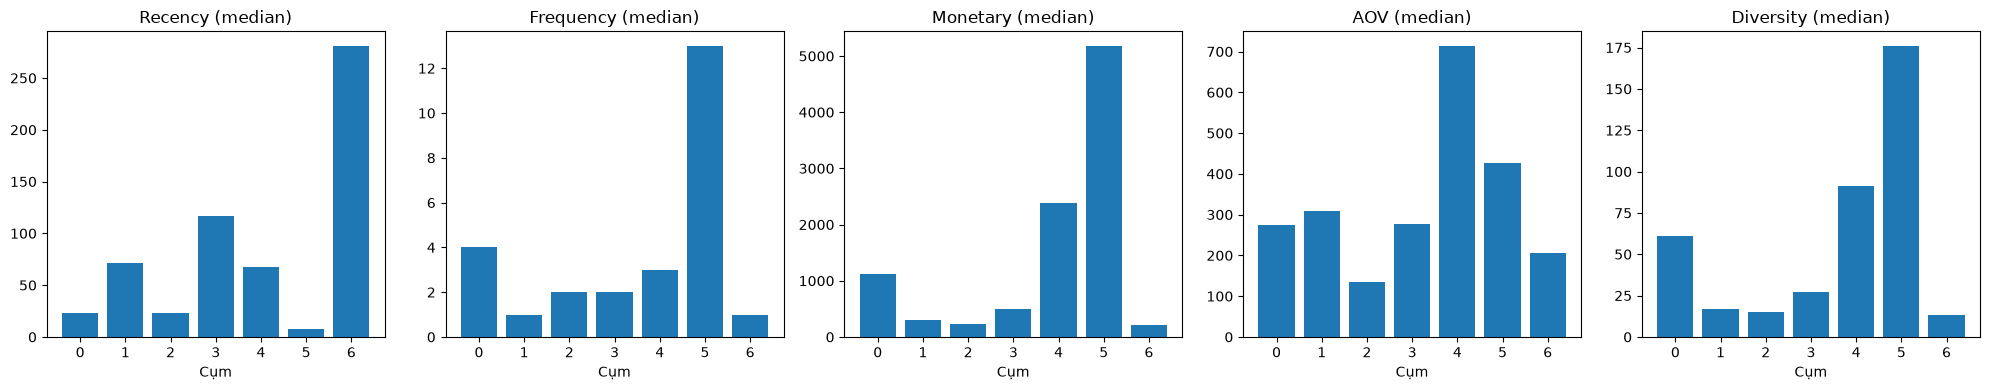

In [9]:
# Hình 1: PC1-PC2 (không gian mô hình có 3 PC; hình chiếu lên 2 trục đầu)
centers = gm.means_
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=16, alpha=0.6, rasterized=True)
ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=160, edgecolors="white", linewidths=1.2,
           label="Trung bình thành phần")
ax.set_xlabel(f"PC1 ({prep['pca'].explained_variance_ratio_[0]:.1%} phương sai)")
ax.set_ylabel(f"PC2 ({prep['pca'].explained_variance_ratio_[1]:.1%} phương sai)")
ax.set_title(f"D01-GN — chiếu lên PC1-PC2 (mô hình dùng {n_pc} PC, k={gm.n_components}, {gm.covariance_type})")
ax.legend(loc="best"); fig.colorbar(sc, ax=ax, label="Cụm", ticks=sorted(np.unique(labels)))
fig.tight_layout(); fig.savefig(FIG / "gmm_clusters_pca.png", dpi=150, bbox_inches="tight"); plt.show()

# Hình 2: số khách mỗi cụm
cnt = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(cnt.index.astype(str), cnt.values); ax.bar_label(bars)
ax.set_xlabel("Cụm"); ax.set_ylabel("Số khách"); ax.set_title("D01-GN — số khách mỗi cụm")
plt.tight_layout(); fig.savefig(FIG / "gmm_cluster_distribution.png", dpi=150); plt.show()

# Hình 3: trung vị 5 feature từng cụm (thang gốc)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, f in zip(axes, FEATURES):
    ax.bar(prof.index.astype(str), prof[f]); ax.set_title(f + " (median)"); ax.set_xlabel("Cụm")
plt.tight_layout(); fig.savefig(FIG / "gmm_feature_comparison.png", dpi=150); plt.show()

**Nhận xét:** Trên mặt phẳng PC1-PC2 các cụm nằm đè lên nhau, khớp với 73,4% khách có xác suất cụm < 0,8. Biểu đồ trung vị cho thấy cụm 5 nổi bật ở Frequency, Monetary và Diversity, cụm 4 ở AOV, cụm 6 ở Recency; các cụm còn lại phân biệt chủ yếu nhờ Recency và Frequency.

## Kiểm chứng và đối chiếu C01

Ba việc, tính lại bằng chính code ở trên: (1) tái hiện D03-GN của Thuận (cap P99.5) để kiểm tra bước cap và pipeline khớp nhóm; (2) so cấu hình được chọn với E03-GN của Thuận (cap P99, lọc tương quan 0,95, không loại biến nào); (3) dựng lại C01 (không cap) để thấy riêng tác động của winsorization. Vì hai thí nghiệm nằm trên hai không gian khác nhau, bảng còn tính Silhouette của mỗi cách chia trên **cả hai không gian**.

In [10]:
# (1) Tái hiện D03-GN của Thuận: cap P99.5, fit đúng cấu hình ông đã chọn
th_d03 = json.load(open(find("notebooks/03_clustering_eval/19-11-2026-thuan-gmm-d03/data/gmm_d03_params.json"), encoding="utf8"))
caps_d03 = X.quantile(0.995); caps_d03[["Recency"]] = np.inf
_, Z_d03, _, _, n_d03 = build_space(caps_d03.to_numpy())
gm_d03 = fit_gmm(Z_d03, th_d03["k"], th_d03["covariance_type"])
print(f"(1) D03-GN của Thuận: k={th_d03['k']} {th_d03['covariance_type']}, BIC={th_d03['bic']:,.2f}")
print(f"    Tính lại ở đây   : k={gm_d03.n_components} {gm_d03.covariance_type}, BIC={gm_d03.bic(Z_d03):,.2f}, {n_d03} PC")
print("    Khớp:", abs(gm_d03.bic(Z_d03) - th_d03["bic"]) < 0.01)

# (2) E03-GN của Thuận (cap P99 + lọc tương quan 0,95)
th_e03 = json.load(open(find("notebooks/03_clustering_eval/19-11-2026-thuan-gmm-e03/data/gmm_e03_params.json"), encoding="utf8"))
same_e03 = (th_e03["k"] == int(best["k"]) and th_e03["covariance_type"] == best["covariance_type"]
            and abs(th_e03["bic"] - best["BIC"]) < 0.01 and th_e03["min_cluster"] == int(best["min_cluster"]))
print(f"\n(2) E03-GN của Thuận: k={th_e03['k']} {th_e03['covariance_type']}, BIC={th_e03['bic']:,.2f}, "
      f"Silhouette={th_e03['silhouette']:.4f}, cụm nhỏ nhất={th_e03['min_cluster']}, loại biến: {th_e03.get('dropped_features')}")
print(f"    D01-GN (ở đây)  : k={int(best['k'])} {best['covariance_type']}, BIC={best['BIC']:,.2f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")
print("    Trùng hoàn toàn:", same_e03)

(1) D03-GN của Thuận: k=7 full, BIC=36,866.27
    Tính lại ở đây   : k=7 full, BIC=36,866.27, 3 PC
    Khớp: True

(2) E03-GN của Thuận: k=7 full, BIC=36,888.95, Silhouette=0.1416, cụm nhỏ nhất=341, loại biến: []
    D01-GN (ở đây)  : k=7 full, BIC=36,888.95, Silhouette=0.1416, cụm nhỏ nhất=341
    Trùng hoàn toàn: True


In [11]:
# (3) C01 dựng lại: không cap (a_max = vô cực), cùng lưới và quy tắc
_, Z_c01, _, cum_c01, n_c01 = build_space(np.full(len(FEATURES), np.inf))
res_c01 = sweep(Z_c01); best_c01 = select(res_c01, len(X))
gm_c01 = fit_gmm(Z_c01, best_c01["k"], best_c01["covariance_type"]); labels_c01 = gm_c01.predict(Z_c01)
ref = json.load(open(find("notebooks/03_clustering_eval/18-11-2026-Nguyen-gmm-c01/gmm_params.json"), encoding="utf8"))
print(f"(3) C01 dựng lại: {n_c01}/5 PC | {best_c01['covariance_type']}, k={int(best_c01['k'])}, BIC={best_c01['BIC']:,.1f}")
print(f"    C01-GN đã lưu: {ref['n_components']} PC | {ref['covariance_type']}, k={ref['k']}, BIC={ref['bic']:,.1f}")
print("    Khớp:", n_c01 == ref["n_components"] and best_c01["covariance_type"] == ref["covariance_type"]
      and int(best_c01["k"]) == ref["k"] and round(best_c01["BIC"], 1) == round(ref["bic"], 1))

def line(name, n_components, gm_, Zs, lab):
    return {"Thí nghiệm": name, "Số PC": n_components, "covariance": gm_.covariance_type, "k": gm_.n_components,
            "BIC": round(gm_.bic(Zs), 1), "Silhouette": round(silhouette_score(Zs, lab), 4),
            "DBI": round(davies_bouldin_score(Zs, lab), 4), "CHI": round(calinski_harabasz_score(Zs, lab), 1),
            "Khách xác suất < 0,8 (%)": round(100 * (gm_.predict_proba(Zs).max(axis=1) < 0.8).mean(), 1),
            "Kích thước cụm": sorted(np.bincount(lab).tolist(), reverse=True),
            "Silhouette trên không gian C01": round(silhouette_score(Z_c01, lab), 4),
            "Silhouette trên không gian D01": round(silhouette_score(Z, lab), 4)}

cmp = pd.DataFrame([line("C01-GN (dựng lại)", n_c01, gm_c01, Z_c01, labels_c01), line("D01-GN", n_pc, gm, Z, labels)])
ari = adjusted_rand_score(labels_c01, labels)
print("\nARI giữa cách chia C01 và D01:", round(ari, 4))
print("Bảng chéo (hàng: cụm C01, cột: cụm D01):")
print(pd.crosstab(pd.Series(labels_c01, name="C01"), pd.Series(labels, name="D01")).to_string())
cmp

(3) C01 dựng lại: 3/5 PC | full, k=6, BIC=36,807.8
    C01-GN đã lưu: 3 PC | full, k=6, BIC=36,807.8
    Khớp: True

ARI giữa cách chia C01 và D01: 0.4914
Bảng chéo (hàng: cụm C01, cột: cụm D01):
D01     0    1    2    3    4    5    6
C01                                    
0     125   11  422   78   11    1    0
1    1149    0    0   73  111  305    0
2      38    0   24  353  194    0    0
3       1    0   17    0    2   99    0
4       0  475    3   16    0    0  163
5       0    2   26  169   23    0  436


,Thí nghiệm,Số PC,covariance,k,BIC,Silhouette,DBI,CHI,"Khách xác suất < 0,8 (%)",Kích thước cụm,Silhouette trên không gian C01,Silhouette trên không gian D01
0,C01-GN (dựng lại),3,full,6,36807.8,0.0954,1.9924,895.1,69.7,"[1638, 657, 656, 648, 609, 119]",0.0954,0.0854
1,D01-GN,3,full,7,36889.0,0.1416,1.8113,1173.0,73.4,"[1313, 689, 599, 492, 488, 405, 341]",0.1418,0.1416


**Nhận xét:**
- **Pipeline khớp nhóm:** tái hiện D03-GN của Thuận (cap P99.5) cho đúng BIC 36.866,27 và số PC; dựng lại C01 khớp C01-GN đã lưu.
- **D01-GN trùng hoàn toàn E03-GN của Thuận** (full, k = 7, BIC 36.888,95, cụm nhỏ nhất 341): E03 dùng cap P99 và lọc tương quan ở ngưỡng 0,95 nhưng không loại biến nào (|Spearman| lớn nhất 0,8094), nên cùng tập feature và cùng kết quả với D01. Theo cách bảng chiến lược định nghĩa (E01–E03 chỉ khác D01 ở ngưỡng lọc), **E01-GN cũng tương đương D01-GN**; Thuận cũng báo E02 không loại biến nào.
- **Winsorization đổi cách chia khá nhiều:** ARI giữa C01 và D01 là 0,4914. C01 chọn k = 6 (cụm nhỏ nhất 119 khách); D01 chọn k = 7 với cụm nhỏ nhất 341 khách và nhóm hàng đầu 405 khách thay vì nhóm nhỏ 119 khách.
- **Cụm gọn hơn trên cả hai không gian:** trên không gian C01, Silhouette của cách chia D01 là 0,1418 so với 0,0954 của C01; trên không gian D01, 0,1416 so với 0,0854. Silhouette trên không gian riêng tăng từ 0,0954 lên 0,1416 và DBI giảm từ 1,9924 xuống 1,8113.
- **Nhưng vẫn chồng lấn rất nhiều:** 73,4% khách có xác suất cụm < 0,8 (C01: 69,7%) và Silhouette chỉ 0,14, còn thấp xa B01-GN (0,3082, chỉ RFM). Cap cải thiện chất lượng so với C01 chứ chưa giải quyết được chồng lấn do thêm AOV và Diversity.
- **Nhóm hàng đầu lớn hơn ở D01:** 405 khách (9,4%) giữ 55,1% Monetary gốc, trong khi C01 tách một nhóm nhỏ hơn nhiều (119 khách, 36,8%). Nhiều khả năng do cap nén khoảng cách của khách ở đuôi nên họ không bị tách riêng thành một cụm cực nhỏ; thí nghiệm này chưa tách riêng được cơ chế đó nên đây chỉ là giả thuyết.

## Lưu kết quả

In [12]:
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_d01_labels.csv", index=False)
joblib.dump(model, "gmm_model.pkl")

params = {"experiment": "D01-GN", "features": FEATURES, "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "cap_percentile": CAP_Q, "cap_features": CAP_FEATURES,
          "caps": {k: (None if np.isinf(v) else float(v)) for k, v in caps.items()}, "customers_capped": n_capped,
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "covariance_type": best["covariance_type"], "k": int(best["k"]),
          "bic": float(best["BIC"]), "aic": float(best["AIC"]), "silhouette": float(best["Silhouette"]),
          "dbi": float(best["DBI"]), "chi": float(best["CHI"]), "min_cluster": int(best["min_cluster"]),
          "converged": bool(gm.converged_), "n_iter": int(gm.n_iter_), "n_customers": int(len(X)),
          "equivalent_to": "E03-GN (Thuận): cùng cap P99, không loại biến nào; E01-GN tương đương theo cùng lý do",
          "ari_vs_c01": round(float(ari), 4), "gmm_params": gm.get_params()}
json.dump(params, open("gmm_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in Path(".").iterdir() if p.is_file()), sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['Working_details_GMM_D01.xlsx', 'gmm_d01.ipynb', 'gmm_model.pkl', 'gmm_params.json'] ['gmm_d01_labels.csv']


## Working_details

Ghi bảng tóm tắt theo bố cục `Working_details_GMM_RFM.xlsx` của Thuận (và B01-GN, C01-GN): sheet chính (thiết lập, bảng quét `covariance_type × k`, bảng cụm), sheet `So_sanh_cau_hinh` và sheet `Cap` (bảng ngưỡng cap).

In [13]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "GMM_D01"
B = Font(name="Calibri", bold=True)
def put(sheet, cell, value, bold=False, fmt=None):
    sheet[cell] = value
    sheet[cell].font = B if bold else Font(name="Calibri")
    if fmt: sheet[cell].number_format = fmt

n = len(X)
put(ws, "A1", "THÍ NGHIỆM GMM — D01 (RFM + AOV + Diversity, cap P99, log1p, Standard, PCA 90%)", bold=True)
put(ws, "A2", "Trạng thái", bold=True)
put(ws, "B2", "Đã chạy xong; BIC/AIC/Silhouette/DBI/CHI tính trên Z (không gian cap P99 + log1p + Standard + PCA 90%)")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(ws, f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary, AOV, Diversity"),
        ("Dữ liệu train", f"Z (cap P99 → log1p → Standard → PCA 90%, {n_pc} PC)"),
        ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv"),
        ("covariance_type", best["covariance_type"]), ("k được chọn", int(best["k"])),
        ("random_state", RANDOM_STATE), ("n_init", N_INIT), ("init_params", INIT_PARAMS)]
right = [("max_iter", MAX_ITER), ("tol", TOL), ("reg_covar", REG_COVAR), ("Tổng khách hàng", int(n)),
         ("Số vòng EM", int(gm.n_iter_)), ("Hội tụ", bool(gm.converged_)),
         ("Quy tắc chọn", "BIC thấp nhất, mỗi cụm >= 1% số khách"),
         ("PCA", f"{n_pc}/{len(FEATURES)} PC, phương sai {cum[n_pc-1]:.2%}")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(ws, f"A{i}", a); put(ws, f"B{i}", b); put(ws, f"D{i}", d); put(ws, f"E{i}", e)
put(ws, "A13", "Winsorization")
put(ws, "B13", f"P{CAP_Q} trên Frequency, Monetary, AOV, Diversity (giữ Recency); {n_capped} khách ({100*n_capped/n:.2f}%) bị cap; không xóa khách")

hdr = ["covariance_type", "k", "BIC", "AIC", "Silhouette", "DBI", "CHI", "Cụm nhỏ nhất", "Nhận xét"]
for c, v in zip("ABCDEFGHI", hdr): put(ws, f"{c}14", v, bold=True)
for i, r in enumerate(res.itertuples(), start=15):
    if r.covariance_type == best["covariance_type"] and r.k == int(best["k"]): note = "được chọn"
    elif not r.converged: note = "không hội tụ"
    elif r.min_cluster < MIN_CLUSTER_FRAC * n: note = "loại: cụm nhỏ nhất < 1% số khách"
    else: note = ""
    vals = [r.covariance_type, int(r.k), round(r.BIC, 2), round(r.AIC, 2), round(r.Silhouette, 4), round(r.DBI, 4),
            round(r.CHI, 2), int(r.min_cluster), note]
    fmts = [None, None, "0.00", "0.00", "0.0000", "0.0000", "0.00", None, None]
    for c, v, f in zip("ABCDEFGHI", vals, fmts): put(ws, f"{c}{i}", v, fmt=f)

r0 = 15 + len(res) + 1
for c, v in zip("ABCDEFGHIJ", ["Cụm", "Mô tả (so với trung vị chung)", "Số khách", "Tỷ lệ (%)", "Recency (median)",
                                "Frequency (median)", "Monetary (median)", "AOV (median)", "Diversity (median)",
                                "Tỷ trọng Monetary (%)"]):
    put(ws, f"{c}{r0}", v, bold=True)
med = X.median()
def mo_ta(p):
    return ("Recency xa (lâu chưa mua)" if p["Recency"] > med["Recency"] else "Recency gần") + ", " + \
           ("Frequency cao" if p["Frequency"] > med["Frequency"] else "Frequency thấp") + ", " + \
           ("Monetary cao" if p["Monetary"] > med["Monetary"] else "Monetary thấp")
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    put(ws, f"A{j}", int(cl)); put(ws, f"B{j}", mo_ta(p)); put(ws, f"C{j}", int(p["customers"]))
    put(ws, f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(ws, f"E{j}", float(p["Recency"]))
    put(ws, f"F{j}", float(p["Frequency"])); put(ws, f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(ws, f"H{j}", float(p["AOV"]), fmt="0.00"); put(ws, f"I{j}", float(p["Diversity"]))
    put(ws, f"J{j}", float(p["Monetary_share_pct"]), fmt="0.00")
for col, w in zip("ABCDEFGHIJ", [16, 22, 17, 19, 20, 21, 25, 22, 18, 22]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"

ws2 = wb.create_sheet("So_sanh_cau_hinh")
cols2 = ["Thí nghiệm", "Số PC", "covariance", "k", "BIC", "Silhouette", "DBI", "CHI", "Khách xác suất < 0,8 (%)",
         "Silhouette trên không gian C01", "Silhouette trên không gian D01", "Kích thước cụm"]
letters = "ABCDEFGHIJKL"
for c, v in zip(letters, cols2): put(ws2, f"{c}1", v, bold=True)
for i, r in enumerate(cmp.itertuples(index=False), start=2):
    vals = [r[0], int(r[1]), r[2], int(r[3]), float(r[4]), float(r[5]), float(r[6]), float(r[7]), float(r[8]),
            float(r[10]), float(r[11]), str(r[9])]
    for c, v in zip(letters, vals): put(ws2, f"{c}{i}", v)
put(ws2, "A5", "BIC và Silhouette tính trên không gian khác nhau của từng dòng nên không so trực tiếp; hai cột Silhouette 'trên không gian' là phép so cùng không gian.")
put(ws2, "A6", f"ARI giữa cách chia C01 (dựng lại) và D01: {ari:.4f}")
put(ws2, "A7", f"Trùng hoàn toàn E03-GN (Thuận): {same_e03} (cap P99, ngưỡng tương quan 0,95, không loại biến nào) nên E01-GN tương đương D01-GN.")
put(ws2, "A8", f"Tái hiện D03-GN (Thuận, cap P99.5): BIC {gm_d03.bic(Z_d03):,.2f} so với {th_d03['bic']:,.2f} của Thuận.")
for col, w in zip(letters, [24, 8, 12, 6, 12, 12, 10, 10, 24, 28, 28, 44]): ws2.column_dimensions[col].width = w

ws3 = wb.create_sheet("Cap")
for c, v in zip("ABCDE", ["Biến", f"Ngưỡng cap (P{CAP_Q})", "Số khách bị cap", "Tỷ lệ khách bị cap (%)", "Giá trị bị cắt (% tổng)"]):
    put(ws3, f"{c}1", v, bold=True)
for i, (feat, r) in enumerate(cap_report.iterrows(), start=2):
    put(ws3, f"A{i}", feat)
    put(ws3, f"B{i}", "không cap" if np.isnan(r["cap"]) else float(r["cap"]), fmt="0.00")
    put(ws3, f"C{i}", int(r["customers_capped"])); put(ws3, f"D{i}", float(r["customers_capped_pct"]), fmt="0.00")
    put(ws3, f"E{i}", float(r["value_capped_pct"]), fmt="0.00")
put(ws3, f"A{len(cap_report) + 3}", f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / n:.2f}%); không xóa khách nào ({n} khách còn nguyên).")
for col, w in zip("ABCDE", [14, 20, 18, 24, 24]): ws3.column_dimensions[col].width = w

wb.save("Working_details_GMM_D01.xlsx")
print("Đã lưu Working_details_GMM_D01.xlsx")

Đã lưu Working_details_GMM_D01.xlsx


## Kết luận D01-GN

- **GMM chọn `full`, k = 7** (BIC 36.888,95), cụm nhỏ nhất 341 khách, hội tụ sau 31 vòng EM; cực tiểu BIC rõ hơn C01 (thấp hơn k lân cận từ 31 điểm trở lên) và không chạm biên lưới.
- **Winsorization P99 đổi cách chia so với C01** (ARI 0,4914): cắt đuôi của 116 khách (2,68%) cắt đi 21,62% tổng Monetary, và nhóm khách hàng đầu thành một cụm lớn 405 khách (9,4%) giữ 55,1% Monetary, thay vì nhóm nhỏ 119 khách của C01. Silhouette tăng từ 0,0954 lên 0,1416 và DBI giảm từ 1,9924 xuống 1,8113; cách chia D01 gọn hơn trên cả hai không gian.
- **Vẫn chồng lấn nhiều:** 73,4% khách có xác suất cụm < 0,8 và Silhouette 0,14 vẫn thấp xa B01-GN (0,3082); cap giúp so với C01 nhưng chưa bù được ảnh hưởng của AOV và Diversity.
- **Trùng E03-GN của Thuận** (và theo cùng lý do tương đương E01-GN): lọc tương quan ở ngưỡng 0,85–0,95 không loại biến nào (|Spearman| lớn nhất 0,8094), nên E01–E03 không cho thông tin mới ngoài D01.
- **Bước kế tiếp:** D02-KM (cap P95), D04-DB (cap P99 cộng RobustScaler) và E04-DB (cap P99, không PCA) so với kết quả này.